<a href="https://colab.research.google.com/github/hitengahlawat/Customer-Churn-Prediction-modal/blob/main/Customer_churn_pridictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***EDA AND DATA CLEANING***

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['customerID'].duplicated().sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [ ]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df["TotalCharges"].dtype

dtype('O')

In [ ]:
(df["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"

)

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
df.loc[df["TotalCharges"].isnull(),
           ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [ ]:
df['TotalCharges']=df['tenure']*df['MonthlyCharges']

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [ ]:
df.shape

(7043, 21)

In [ ]:
churn_rate=df.groupby("Contract")["Churn"].apply(lambda x: (x=="Yes").mean()*100)
churn_rate


,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


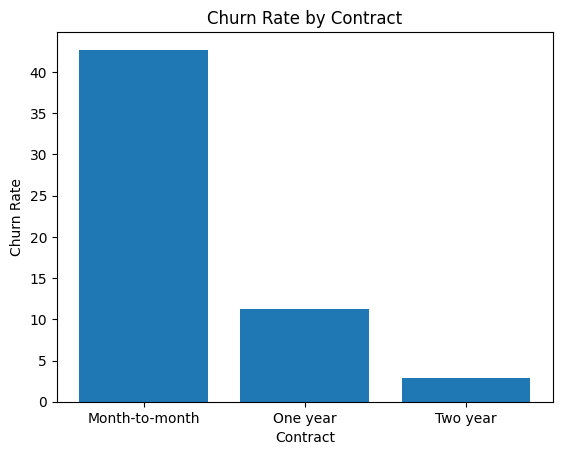

In [ ]:
plt.bar(churn_rate.index, churn_rate.values)
plt.xlabel("Contract")
plt.ylabel("Churn Rate")
plt.title("Churn Rate by Contract")
plt.show()

DATA PREPARING FOR ML MODEL


In [ ]:
df=df.drop("customerID" ,axis=1)

In [ ]:
x=df.drop("Churn",axis=1)
y=df["Churn"]

In [ ]:
y = y.map({"Yes": 1, "No": 0})

In [ ]:
y.isna().sum()

np.int64(0)

In [ ]:
x.select_dtypes(include="object").columns.tolist()

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [ ]:
categorical_cols = x.select_dtypes(include="object").columns.tolist()
numerical_cols = x.select_dtypes(include="number").columns.tolist()

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(x_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8211497515968772

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409


Confusion Matrix:

[[935 101]
 [151 222]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score,confusion_matrix

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))
print("confusinon matrin\n")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 0.7934705464868701

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.46      0.54       373

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.70      1409
weighted avg       0.78      0.79      0.78      1409

confusinon matrin

[[945  91]
 [200 173]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get predicted probabilities for churn (class 1)
y_prob = model.predict_proba(x_test)[:, 1]

# Try a lower threshold
threshold = 0.15



y_pred_new = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_new))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_new))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_new))

Threshold: 0.15
Accuracy: 0.6692689850958127

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.57      0.72      1036
           1       0.44      0.94      0.60       373

    accuracy                           0.67      1409
   macro avg       0.70      0.76      0.66      1409
weighted avg       0.82      0.67      0.69      1409


Confusion Matrix:
[[593 443]
 [ 23 350]]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
y_prob = model.predict_proba(x_test)[:, 1]

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40]:
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall:", round(recall_score(y_test, y_pred), 3))
    print("F1-score:", round(f1_score(y_test, y_pred), 3))


Threshold: 0.2
Precision: 0.466
Recall: 0.874
F1-score: 0.608

Threshold: 0.25
Precision: 0.509
Recall: 0.847
F1-score: 0.636

Threshold: 0.3
Precision: 0.555
Recall: 0.804
F1-score: 0.656

Threshold: 0.35
Precision: 0.571
Recall: 0.74
F1-score: 0.645

Threshold: 0.4
Precision: 0.602
Recall: 0.702
F1-score: 0.649


In [ ]:
import joblib

joblib.dump(model, "churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
joblib.dump(0.30, "churn_threshold.pkl")

['churn_threshold.pkl']

In [ ]:
import sklearn
print(sklearn.__version__)


1.6.1
